# Stress results

This notebook runs the five illustrative scenarios with the coverage tests off and on, and ends with one table and one chart. Terms are defined in 01_how_the_deal_works.ipynb.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from waterfall import DEAL, SCENARIOS, run_pool, run_waterfall, summarize_tranches, break_even_cdr

pd.options.display.float_format = "{:,.2f}".format

The scenarios: CPR (annual prepayment rate), CDR (annual default rate) and severity (share of a default that is lost). All are illustrative assumptions.

In [2]:
pd.DataFrame(SCENARIOS).T

,cpr,cdr,severity
base,0.10,0.01,0.35
high_default,0.10,0.03,0.35
high_severity,0.10,0.01,0.55
slow_prepay,0.05,0.01,0.35
combined,0.05,0.03,0.55


Run each scenario once through the pool and twice through the waterfall, tests off and tests on. Keep the pool and the tranche summary of every run.

In [3]:
pools = {}
summaries = {}
for name, scenario in SCENARIOS.items():
    pools[name] = run_pool(DEAL, scenario["cpr"], scenario["cdr"], scenario["severity"])
    for tests_on in [False, True]:
        waterfall = run_waterfall(DEAL, pools[name], tests_on)
        label = "tests on" if tests_on else "tests off"
        summaries[(name, label)] = summarize_tranches(DEAL, waterfall)

Total pool loss by scenario, before the waterfall. The $4 million residual absorbs losses first, so the notes are only written down once losses pass $4 million.

In [4]:
total_loss = {}
for name, pool in pools.items():
    total_loss[name] = pool["loss"].sum()
pd.Series(total_loss, name="total_loss")

base             2,572,958.11
high_default     6,879,827.87
high_severity    4,043,219.89
slow_prepay      3,826,921.69
combined        15,475,524.57
Name: total_loss, dtype: float64

One full tranche summary as an example: the combined scenario with tests on.

In [5]:
summaries[("combined", "tests on")]

,original_balance,principal_paid,writedown,writedown_pct,wal_years,interest_shortfall
tranche,,,,,,
A,80000000,"80,000,000.00",0.00,0.00,7.67,0.00
B,10000000,"10,000,000.00",0.00,0.00,24.24,0.00
C,6000000,"377,953.14","5,622,046.86",93.70,29.77,"1,808,958.88"


Save the combined scenario with tests on to Excel: one sheet, one row per month, every pool and waterfall column, so each month can be traced by hand.

In [6]:
combined_waterfall = run_waterfall(DEAL, pools["combined"], tests_on=True)
trace = pools["combined"].join(combined_waterfall)
trace.to_excel("combined_scenario.xlsx", sheet_name="combined_tests_on")
print("rows, columns:", trace.shape)

rows, columns: (366, 37)


Headline table: write-down as a percent of original balance and WAL in years, per tranche, per scenario, tests off and tests on. A WAL of NaN means the tranche never received any principal.

In [7]:
rows = []
for (name, label), summary in summaries.items():
    row = {"scenario": name, "tests": label}
    for tranche in ["A", "B", "C"]:
        row[tranche + " write-down %"] = summary.loc[tranche, "writedown_pct"]
        row[tranche + " WAL years"] = summary.loc[tranche, "wal_years"]
    rows.append(row)
headline = pd.DataFrame(rows).set_index(["scenario", "tests"])
headline

A write-down %  A WAL years  B write-down %  \
scenario      tests                                                    
base          tests off            0.00         4.92            0.00   
              tests on             0.00         4.92            0.00   
high_default  tests off            0.00         4.68            0.00   
              tests on             0.00         4.68            0.00   
high_severity tests off            0.00         5.05            0.00   
              tests on             0.00         5.05            0.00   
slow_prepay   tests off            0.00         8.25            0.00   
              tests on             0.00         8.25            0.00   
combined      tests off            0.00         8.62           54.76   
              tests on             0.00         7.67            0.00   

                         B WAL years  C write-down %  C WAL years  
scenario      tests                                                
base          tests off        15.44            0.00        21.60  
              tests on         15.44            0.00        21.60  
high_default  tests off        16.14           48.00        24.30  
              tests on         16.14           48.00        24.30  
high_severity tests off        16.22            0.72        23.67  
              tests on         16.22            0.72        23.67  
slow_prepay   tests off        22.83            0.00        27.72  
              tests on         22.83            0.00        27.72  
combined      tests off        27.21          100.00          NaN  
              tests on         24.24           93.70        29.77

Break-even CDR: the lowest CDR, in 0.1% steps with CPR and severity held at base, at which each tranche takes its first write-down. The search reruns the model many times, so this cell takes a minute or two.

In [8]:
break_even = pd.DataFrame(index=["A", "B", "C"], columns=["tests off", "tests on"], dtype=float)
for tranche in ["A", "B", "C"]:
    break_even.loc[tranche, "tests off"] = break_even_cdr(DEAL, tranche, tests_on=False)
    break_even.loc[tranche, "tests on"] = break_even_cdr(DEAL, tranche, tests_on=True)
break_even_pct = 100 * break_even
break_even_pct.index.name = "break-even CDR %"
break_even_pct

,tests off,tests on
break-even CDR %,,
A,14.60,19.10
B,4.80,7.50
C,1.70,1.70


Headline chart: write-down by tranche and scenario, tests off on the left and tests on on the right. The method xs picks the rows of the headline table for one tests setting. The chart is saved as results.png.

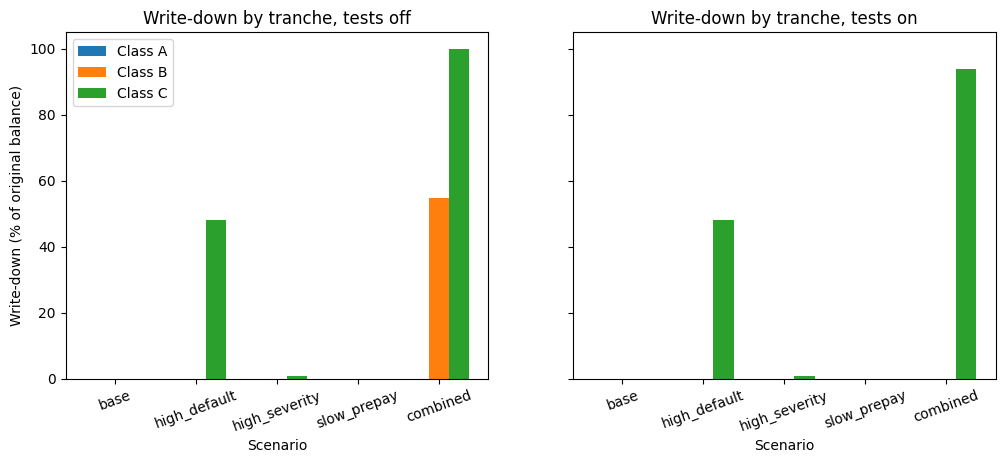

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
positions = np.arange(len(SCENARIOS))
for ax, label in zip(axes, ["tests off", "tests on"]):
    for offset, tranche in zip([-0.25, 0.0, 0.25], ["A", "B", "C"]):
        values = headline.xs(label, level="tests")[tranche + " write-down %"]
        ax.bar(positions + offset, values, width=0.25, label="Class " + tranche)
    ax.set_title("Write-down by tranche, " + label)
    ax.set_xticks(positions, list(SCENARIOS), rotation=20)
    ax.set_xlabel("Scenario")
axes[0].set_ylabel("Write-down (% of original balance)")
axes[0].legend()
fig.savefig("results.png", dpi=150, bbox_inches="tight")
plt.show()